# 289. Dark set at E < 1 vs E < 10: how many proteins the sequence tools miss, and how many kmerseek reaches

**Question.** The dark set is the proteins of a proteome that phmmer, jackhmmer and mmseqs2
all fail to place in Swiss-Prot. "Fail" depends on an E-value cutoff (the number of hits
this good expected by chance in the whole database), and so does "kmerseek reaches a
protein". How do the dark set and kmerseek's reach of it change between E < 1 and E < 10?

**Decision this informs.** Which cutoff the paper's dark-set numbers use, and whether the
best kmerseek settings (alphabet, k-mer size, scaled) must be picked again at that cutoff.

**Decision rule** (written after a first look at the per-species medians in section 2, so
it is not blind to them). Rank the settings of each species by the share of dark proteins
they reach. If the 10 settings on top at E < 1 and at E < 10 share at least 7 in every
species, the best settings do not depend on the cutoff, and the setting choice made at
either cutoff carries over. Otherwise the settings must be picked again at the cutoff the
paper uses.

What this notebook cannot say: whether a protein reached at E < 10 is a real homolog. A
region at E < 10 can be chance; notebook 263 found 38% of E < 10 zebrafish calls also on
shuffled queries. Telling the two apart needs that shuffled-query control on this run.

**Data.** Dark-set midi run `ladder-0.4-midi` (PR 57,
[seanome/2024-kmerseek-analysis#57](https://github.com/seanome/2024-kmerseek-analysis/pull/57)):
kmerseek searches 2026-09-30 to 2026-10-10, image `olgabot/kmerseek:0.4.0-rc5`, every
`extend` setting of 19 alphabets at every other k of each alphabet's range, scaled 1 and 10,
low-complexity mask off. The queries.tsv files were rebuilt by `repairQueriesTsv` on
2026-10-12 (commit 0dad375; before it, any protein with one region at E = inf lost its
finite E-values). Per-protein best E-values exported 2026-10-13 by
`tools/export-protein-evalues`, then counted by `tools/summarize-evalue-cutoffs`.

- **Queries:** the whole proteome of each species: human (20_600 proteins), worm
  *C. elegans* (19_819), yeast *S. cerevisiae* (6_049), *Borrelia* (1_291), and the tunicate
  *Botryllus schlosseri* (45_339).
- **Target database** (the same for all four tools): reviewed Swiss-Prot with the query's
  own clade removed, so every hit crosses at least a class boundary: minus Mammalia (human),
  Ascidiacea (Botryllus), Chromadorea (worm), Saccharomycetes (yeast), Spirochaetia
  (Borrelia).
- **Cutoffs** are strict: E < 1 and E < 10. The pipeline's own dark set uses E <= cutoff.
  HMMER prints E-values to two significant figures, so some proteins have a best tool hit at
  exactly 1.0 or 10; they are dark here and placed in the pipeline (section 1 counts them).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from PIL import Image

import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(60)

DATA = Path("data/289_dark_set_evalue_cutoffs")
FIGURES = Path("figures/289_dark_set_evalue_cutoffs")
IMAGE = "olgabot/kmerseek:0.4.0-rc5"
RUN = "dark-set midi run ladder-0.4-midi"
CUTOFFS = (1.0, 10.0)
TOP_N = 10  # settings compared at the top of each ranking
MIN_SHARED = 7  # decision rule: at least this many of the TOP_N shared

# Chordates first (human, then the tunicate), then the nematode, the fungus, the bacterium.
SPECIES = ["human", "botryllus", "worm", "yeast", "borrelia"]
SPECIES_LABEL = {
    "human": "human",
    "botryllus": "Botryllus",
    "worm": "worm",
    "yeast": "yeast",
    "borrelia": "Borrelia",
}
CLADE_REMOVED = {
    "human": "Mammalia",
    "botryllus": "Ascidiacea",
    "worm": "Chromadorea",
    "yeast": "Saccharomycetes",
    "borrelia": "Spirochaetia",
}

# Colour = the kmerseek region E-value cutoff; marker = the tool cutoff that defines "dark".
CUTOFF_COLOUR = {1.0: pf.OKABE_ITO["blue"], 10.0: pf.OKABE_ITO["orange"]}
CUTOFF_MARKER = {1.0: "o", 10.0: "^"}
TOOLS_LINE = (
    f"Tools: phmmer, jackhmmer, mmseqs2 (dark set); kmerseek ({IMAGE}, extend). "
    "Query: each proteome. Target: Swiss-Prot minus the query's clade."
)


def save_figure(fig, name):
    # PDF and SVG for print; the PNG is rewritten with a 256-colour palette (PR 105).
    pf.save(fig, FIGURES / name)
    png = (FIGURES / name).with_suffix(".png")
    with Image.open(png) as im:
        dpi = im.info.get("dpi")
        pal = im.convert("RGB").quantize(colors=256, dither=Image.Dither.NONE)
    pal.save(png, optimize=True, **({"dpi": dpi} if dpi else {}))
    print(f"saved {png}")


def setting_label(row):
    return f"{row['alphabet']} k{row['ksize']} scaled {row['scaled']}"

## 1. How big is the dark set at E < 1 and at E < 10?

A protein is **dark** at a cutoff when none of phmmer, jackhmmer and mmseqs2 has a hit for
it with an E-value below the cutoff. A looser cutoff (10) lets weaker hits count as placed,
so the dark set shrinks to the proteins with no hit at all, even a weak one. Fewer dark
proteins is not better or worse by itself: it is a smaller, harder set.

n_dark: no tool hit with E < cutoff. n_best_exactly_at_cutoff: dark proteins whose best tool E-value equals the cutoff.
n_dark_pipeline_rule: the dark set under the pipeline's E <= cutoff. n_<tool>: proteins that tool has a hit for with E < cutoff.
shape: (10, 10)
┌───────────┬────────────┬────────┬────────┬──────────┬──────────────────────────┬──────────────────────┬──────────┬─────────────┬───────────┐
│ species   ┆ n_proteins ┆ cutoff ┆ n_dark ┆ pct_dark ┆ n_best_exactly_at_cutoff ┆ n_dark_pipeline_rule ┆ n_phmmer ┆ n_jackhmmer ┆ n_mmseqs2 │
│ ---       ┆ ---        ┆ ---    ┆ ---    ┆ ---      ┆ ---                      ┆ ---                  ┆ ---      ┆ ---         ┆ ---       │
│ str       ┆ i64        ┆ f64    ┆ i64    ┆ f64      ┆ i64                      ┆ i64                  ┆ i64      ┆ i64         ┆ i64       │
╞═══════════╪════════════╪════════╪════════╪══════════╪══════════════════════════╪══════════════════════╪══════════╪═════════════╪═══════════╡
│ human     ┆ 20600 

saved figures/289_dark_set_evalue_cutoffs/dark_set_size_E1_vs_E10_midi_swissprot.png


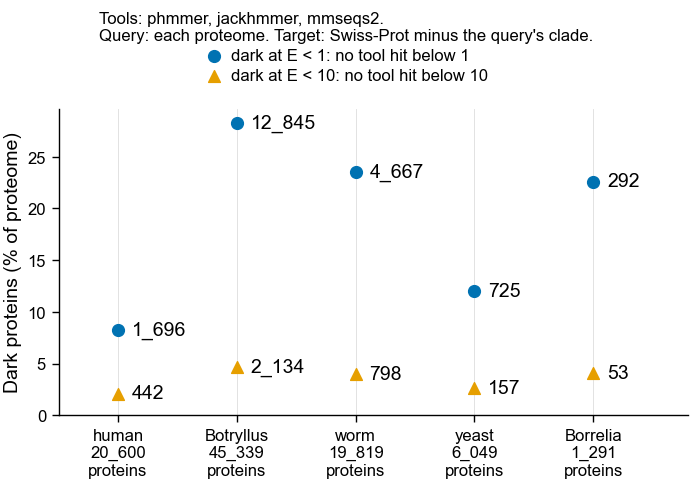

In [2]:
tools = pl.read_csv(DATA / "tool_dark_by_cutoff.csv").filter(
    pl.col("cutoff").is_in(CUTOFFS)
)
dark_size = (
    tools.with_columns(
        (100 * pl.col("n_dark") / pl.col("n_proteins")).round(1).alias("pct_dark"),
        (pl.col("n_dark") - pl.col("n_best_exactly_at_cutoff")).alias(
            "n_dark_pipeline_rule"
        ),
    )
    .select(
        "species",
        "n_proteins",
        "cutoff",
        "n_dark",
        "pct_dark",
        "n_best_exactly_at_cutoff",
        "n_dark_pipeline_rule",
        "n_phmmer",
        "n_jackhmmer",
        "n_mmseqs2",
    )
    .sort(
        pl.col("species").replace_strict({s: i for i, s in enumerate(SPECIES)}),
        "cutoff",
    )
)
print(
    "n_dark: no tool hit with E < cutoff. n_best_exactly_at_cutoff: dark proteins whose best "
    "tool E-value equals the cutoff.\nn_dark_pipeline_rule: the dark set under the pipeline's "
    "E <= cutoff. n_<tool>: proteins that tool has a hit for with E < cutoff."
)
print(dark_size)
wide = dark_size.pivot(on="cutoff", index="species", values="n_dark")
print("\nshrink factor, dark at E < 1 / dark at E < 10:")
print(wide.with_columns((pl.col("1.0") / pl.col("10.0")).round(1).alias("ratio")))

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 62)
x = np.arange(len(SPECIES))
for c in CUTOFFS:
    sub = dark_size.filter(pl.col("cutoff") == c)
    y = [sub.filter(pl.col("species") == s)["pct_dark"].item() for s in SPECIES]
    n = [sub.filter(pl.col("species") == s)["n_dark"].item() for s in SPECIES]
    ax.scatter(
        x,
        y,
        color=CUTOFF_COLOUR[c],
        marker=CUTOFF_MARKER[c],
        s=18,
        zorder=3,
        label=f"dark at E < {c:g}: no tool hit below {c:g}",
    )
    for xi, yi, ni in zip(x, y, n):
        ax.annotate(
            f"{ni:_}",
            (xi, yi),
            xytext=(5, 0),
            textcoords="offset points",
            va="center",
            ha="left",
        )
for xi in x:
    ax.axvline(xi, color="#dddddd", lw=0.3, zorder=0)
n_prot = {s: dark_size.filter(pl.col("species") == s)["n_proteins"][0] for s in SPECIES}
ax.set_xticks(x, [f"{SPECIES_LABEL[s]}\n{n_prot[s]:_}\nproteins" for s in SPECIES])
ax.set_xlim(-0.5, len(SPECIES) - 0.2)
ax.set_ylim(0, None)
ax.set_ylabel("Dark proteins (% of proteome)")
pf.shared_legend(
    fig,
    ncol=1,
    title="Tools: phmmer, jackhmmer, mmseqs2.\nQuery: each proteome. Target: Swiss-Prot minus the query's clade.",
)
save_figure(fig, "dark_set_size_E1_vs_E10_midi_swissprot")

## 2. How much of the dark set and of the placed proteins does each kmerseek setting reach?

Here both cutoffs move together: the dark set is defined at E < 1 or E < 10, and kmerseek
**reaches** a protein when one of its regions has an E-value below the same number.
**Placed** proteins are the rest of the proteome (some tool has a hit below the cutoff).

Each point is one kmerseek setting (alphabet, k, scaled). How to read it: the grey diagonal
is where a setting reaches the same share of dark and placed proteins. Placed proteins have
a known homolog in the target database, so a setting that finds homologs reaches them more
often, and sits below the diagonal. A setting in the top right reaches nearly every protein
of both groups; such a setting is not choosing anything, and its dark-set number means
little. Higher dark reach is only good when placed reach stays above it.

Median, min and max across settings of the % of each group reached (cutoffs matched).
shape: (10, 9)
┌───────────┬─────────────┬────────────┬─────────────────┬──────────────┬──────────────┬───────────────────┬────────────────┬────────────────────────────────────┐
│ species   ┆ dark_cutoff ┆ n_settings ┆ dark_median_pct ┆ dark_min_pct ┆ dark_max_pct ┆ placed_median_pct ┆ placed_max_pct ┆ n_settings_dark_at_or_above_placed │
│ ---       ┆ ---         ┆ ---        ┆ ---             ┆ ---          ┆ ---          ┆ ---               ┆ ---            ┆ ---                                │
│ str       ┆ f64         ┆ u32        ┆ f64             ┆ f64          ┆ f64          ┆ f64               ┆ f64            ┆ u32                                │
╞═══════════╪═════════════╪════════════╪═════════════════╪══════════════╪══════════════╪═══════════════════╪════════════════╪════════════════════════════════════╡
│ human     ┆ 1.0         ┆ 167        ┆ 1.9             ┆ 0.0          ┆ 55.4      

saved figures/289_dark_set_evalue_cutoffs/kmerseek_reach_dark_vs_placed_E1_vs_E10_midi_swissprot.png


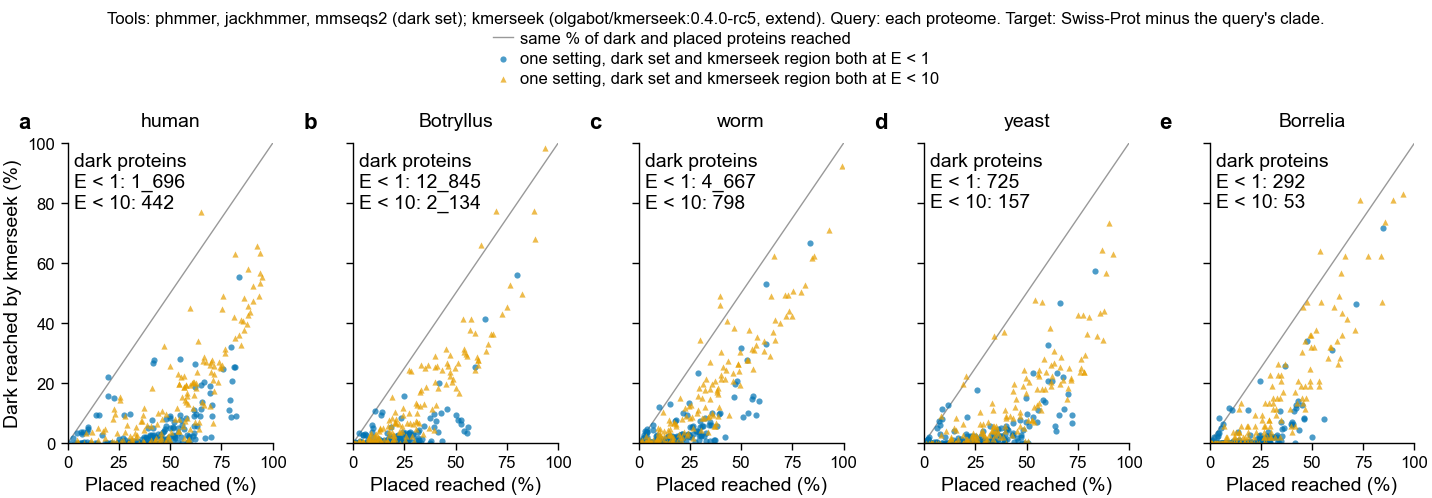

In [3]:
reach = (
    pl.read_csv(DATA / "kmerseek_reach_by_cutoff.csv.gz", infer_schema_length=0)
    .with_columns(
        pl.col("ksize", "scaled", "n_group", "n_reached").cast(pl.Int64),
        pl.col("dark_cutoff").cast(pl.Float64),
    )
    .with_columns((100 * pl.col("n_reached") / pl.col("n_group")).alias("pct"))
)
assert reach["low_complexity_mask"].unique().to_list() == ["false"]
# Matched: the dark set and the region cutoff use the same number.
matched = reach.filter(pl.col("region_cutoff") == pl.col("dark_cutoff").cast(pl.Utf8))
per_setting = matched.pivot(
    on="group",
    index=["species", "alphabet", "ksize", "scaled", "extension", "dark_cutoff"],
    values="pct",
)
summary = (
    per_setting.group_by("species", "dark_cutoff")
    .agg(
        pl.len().alias("n_settings"),
        pl.col("dark").median().round(1).alias("dark_median_pct"),
        pl.col("dark").min().round(1).alias("dark_min_pct"),
        pl.col("dark").max().round(1).alias("dark_max_pct"),
        pl.col("placed").median().round(1).alias("placed_median_pct"),
        pl.col("placed").max().round(1).alias("placed_max_pct"),
        (pl.col("dark") >= pl.col("placed"))
        .sum()
        .alias("n_settings_dark_at_or_above_placed"),
    )
    .sort(
        pl.col("species").replace_strict({s: i for i, s in enumerate(SPECIES)}),
        "dark_cutoff",
    )
)
print(
    "Median, min and max across settings of the % of each group reached (cutoffs matched)."
)
print(summary)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 64, ncols=len(SPECIES), sharex=True, sharey=True)
for ax, s in zip(axs, SPECIES):
    ax.plot(
        [0, 100],
        [0, 100],
        color=pf.GREY,
        lw=0.5,
        zorder=1,
        label="same % of dark and placed proteins reached",
    )
    for c in CUTOFFS:
        sub = per_setting.filter(
            (pl.col("species") == s) & (pl.col("dark_cutoff") == c)
        )
        ax.scatter(
            sub["placed"],
            sub["dark"],
            s=5,
            color=CUTOFF_COLOUR[c],
            marker=CUTOFF_MARKER[c],
            alpha=0.7,
            linewidths=0,
            zorder=2,
            label=f"one setting, dark set and kmerseek region both at E < {c:g}",
        )
    n_dark = {
        c: dark_size.filter((pl.col("species") == s) & (pl.col("cutoff") == c))[
            "n_dark"
        ].item()
        for c in CUTOFFS
    }
    ax.set_title(SPECIES_LABEL[s])
    ax.text(
        0.03,
        0.97,
        f"dark proteins\nE < 1: {n_dark[1.0]:_}\nE < 10: {n_dark[10.0]:_}",
        transform=ax.transAxes,
        va="top",
        ha="left",
    )
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Placed reached (%)")
axs[0].set_ylabel("Dark reached by kmerseek (%)")
pf.shared_legend(fig, ncol=1, title=TOOLS_LINE)
for ax, letter in zip(axs, "abcde"):
    pf.panel_label(ax, letter)
save_figure(fig, "kmerseek_reach_dark_vs_placed_E1_vs_E10_midi_swissprot")

## 3. Which change moves the dark-set reach: the smaller dark set, or the looser kmerseek cutoff?

Going from E < 1 to E < 10 changes two things at once: the dark set shrinks to harder
proteins, and kmerseek's own cutoff loosens. This section changes one at a time. Each point
is the **median across settings** of the % of dark proteins reached; the colour is the
kmerseek region cutoff and the shape is the tool cutoff that defines the dark set, as in
sections 1 and 2.

Median and quartiles across settings of the % of dark proteins kmerseek reaches.
shape: (20, 8)
┌───────────┬─────────────┬───────────────┬────────────┬────────┬─────────────────────────┬──────┬───────┐
│ species   ┆ dark_cutoff ┆ region_cutoff ┆ n_settings ┆ n_dark ┆ median_pct_dark_reached ┆ q25  ┆ q75   │
│ ---       ┆ ---         ┆ ---           ┆ ---        ┆ ---    ┆ ---                     ┆ ---  ┆ ---   │
│ str       ┆ f64         ┆ str           ┆ u32        ┆ i64    ┆ f64                     ┆ f64  ┆ f64   │
╞═══════════╪═════════════╪═══════════════╪════════════╪════════╪═════════════════════════╪══════╪═══════╡
│ human     ┆ 1.0         ┆ 1.0           ┆ 167        ┆ 1696   ┆ 1.89                    ┆ 0.12 ┆ 6.96  │
│ human     ┆ 1.0         ┆ 10.0          ┆ 167        ┆ 1696   ┆ 11.38                   ┆ 1.89 ┆ 30.78 │
│ human     ┆ 10.0        ┆ 1.0           ┆ 167        ┆ 442    ┆ 2.04                    ┆ 0.23 ┆ 6.33  │
│ human     ┆ 10.0        ┆ 10.0          ┆ 167 

saved figures/289_dark_set_evalue_cutoffs/kmerseek_dark_reach_two_cutoffs_separated_midi_swissprot.png


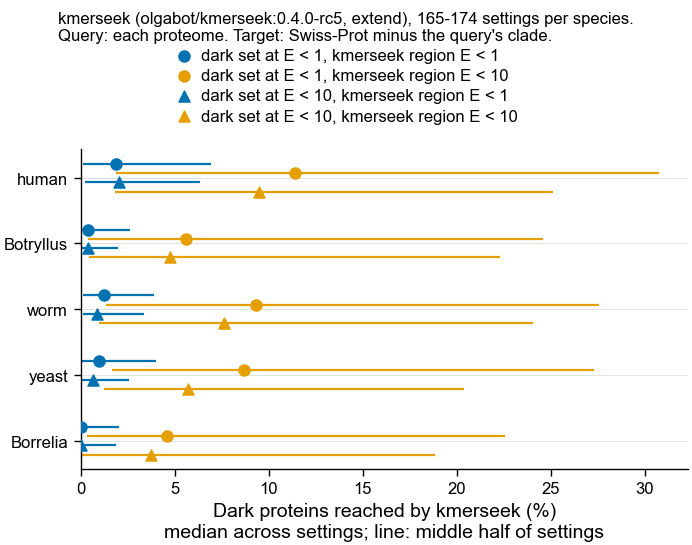

In [4]:
dark_only = reach.filter(
    (pl.col("group") == "dark") & pl.col("region_cutoff").is_in(["1.0", "10.0"])
)
two_by_two = (
    dark_only.group_by("species", "dark_cutoff", "region_cutoff")
    .agg(
        pl.len().alias("n_settings"),
        pl.col("n_group").first().alias("n_dark"),
        pl.col("pct").median().round(2).alias("median_pct_dark_reached"),
        pl.col("pct").quantile(0.25).round(2).alias("q25"),
        pl.col("pct").quantile(0.75).round(2).alias("q75"),
    )
    .sort(
        pl.col("species").replace_strict({s: i for i, s in enumerate(SPECIES)}),
        "dark_cutoff",
        "region_cutoff",
    )
)
print(
    "Median and quartiles across settings of the % of dark proteins kmerseek reaches."
)
print(two_by_two)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
y = np.arange(len(SPECIES))[::-1]
offsets = {
    (1.0, "1.0"): 0.21,
    (1.0, "10.0"): 0.07,
    (10.0, "1.0"): -0.07,
    (10.0, "10.0"): -0.21,
}
for (dc, rc), dy in offsets.items():
    sub = two_by_two.filter(
        (pl.col("dark_cutoff") == dc) & (pl.col("region_cutoff") == rc)
    )
    med = [
        sub.filter(pl.col("species") == s)["median_pct_dark_reached"].item()
        for s in SPECIES
    ]
    lo = [sub.filter(pl.col("species") == s)["q25"].item() for s in SPECIES]
    hi = [sub.filter(pl.col("species") == s)["q75"].item() for s in SPECIES]
    rcf = float(rc)
    ax.hlines(y + dy, lo, hi, color=CUTOFF_COLOUR[rcf], lw=0.8, zorder=2)
    ax.scatter(
        med,
        y + dy,
        color=CUTOFF_COLOUR[rcf],
        marker=CUTOFF_MARKER[dc],
        s=16,
        zorder=3,
        label=f"dark set at E < {dc:g}, kmerseek region E < {rcf:g}",
    )
for yi in y:
    ax.axhline(yi, color="#dddddd", lw=0.3, zorder=0)
ax.set_yticks(y, [SPECIES_LABEL[s] for s in SPECIES])
ax.set_xlim(0, None)
ax.set_xlabel(
    "Dark proteins reached by kmerseek (%)\nmedian across settings; line: middle half of settings"
)
pf.shared_legend(
    fig,
    ncol=1,
    title=f"kmerseek ({IMAGE}, extend), 165-174 settings per species.\n"
    "Query: each proteome. Target: Swiss-Prot minus the query's clade.",
)
save_figure(fig, "kmerseek_dark_reach_two_cutoffs_separated_midi_swissprot")

## 4. Do the same settings come out on top at E < 1 and at E < 10?

The decision rule. For each species and each matched cutoff, settings are sorted by the %
of dark proteins reached (ties broken by lower placed reach, then alphabet, k and scaled,
so the order is fixed). The table lists how many of the top 10 are shared, and how many
settings tie with the 10th, since a tie at the cut makes the top 10 partly arbitrary.

In the figure each point is a setting: the % of dark proteins it reaches at E < 1 (x) and at
E < 10 (y). If the ranking did not depend on the cutoff, the top settings would be the same
points in the top right.

Decision rule: at least 7 of the top 10 shared in every species.
shape: (5, 5)
┌───────────┬────────────────────┬─────────────┬────────────────────────────────┬─────────────────────────────────┐
│ species   ┆ n_shared_of_top_10 ┆ passes_rule ┆ settings_tied_with_10th_at_E<1 ┆ settings_tied_with_10th_at_E<10 │
│ ---       ┆ ---                ┆ ---         ┆ ---                            ┆ ---                             │
│ str       ┆ i64                ┆ bool        ┆ i64                            ┆ i64                             │
╞═══════════╪════════════════════╪═════════════╪════════════════════════════════╪═════════════════════════════════╡
│ human     ┆ 5                  ┆ false       ┆ 1                              ┆ 2                               │
│ botryllus ┆ 4                  ┆ false       ┆ 1                              ┆ 1                               │
│ worm      ┆ 7                  ┆ true        ┆ 1                              ┆ 1                          

saved figures/289_dark_set_evalue_cutoffs/kmerseek_top_settings_E1_vs_E10_midi_swissprot.png


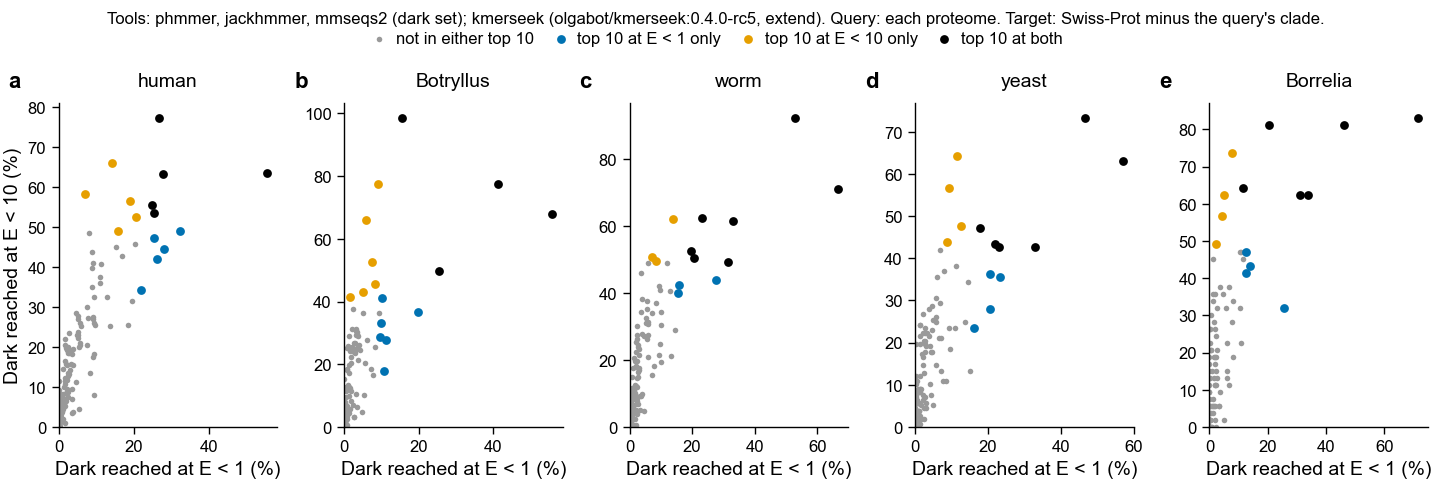

In [5]:
def top_settings(species, cutoff):
    sub = per_setting.filter(
        (pl.col("species") == species) & (pl.col("dark_cutoff") == cutoff)
    ).sort(
        ["dark", "placed", "alphabet", "ksize", "scaled"],
        descending=[True, False, False, False, False],
    )
    tenth = sub["dark"][TOP_N - 1]
    n_tied = sub.filter(pl.col("dark") == tenth).height
    return sub.head(TOP_N), n_tied


keys = ["alphabet", "ksize", "scaled"]
rule_rows, top_rows = [], []
for s in SPECIES:
    (t1, tie1), (t10, tie10) = top_settings(s, 1.0), top_settings(s, 10.0)
    shared = set(t1.select(keys).iter_rows()) & set(t10.select(keys).iter_rows())
    rule_rows.append(
        {
            "species": s,
            "n_shared_of_top_10": len(shared),
            "passes_rule": len(shared) >= MIN_SHARED,
            "settings_tied_with_10th_at_E<1": tie1,
            "settings_tied_with_10th_at_E<10": tie10,
        }
    )
    for c, t in ((1.0, t1), (10.0, t10)):
        for rank, row in enumerate(t.iter_rows(named=True), 1):
            top_rows.append(
                {
                    "species": s,
                    "cutoff": c,
                    "rank": rank,
                    "setting": setting_label(row),
                    "dark_pct": round(row["dark"], 1),
                    "placed_pct": round(row["placed"], 1),
                    "in_top_10_at_both": tuple(row[k] for k in keys) in shared,
                }
            )
rule = pl.DataFrame(rule_rows)
print(
    f"Decision rule: at least {MIN_SHARED} of the top {TOP_N} shared in every species."
)
print(rule)
print("Rule met in every species:", bool(rule["passes_rule"].all()))
top = pl.DataFrame(top_rows)
print("\nTop 10 settings per species and cutoff (kmerseek extend, mask off):")
print(top)

wide = per_setting.pivot(
    on="dark_cutoff", index=["species", "alphabet", "ksize", "scaled"], values="dark"
).rename({"1.0": "dark_E1", "10.0": "dark_E10"})
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 62, ncols=len(SPECIES))
cats = [
    ("not in either top 10", pf.GREY, 4),
    ("top 10 at E < 1 only", CUTOFF_COLOUR[1.0], 10),
    ("top 10 at E < 10 only", CUTOFF_COLOUR[10.0], 10),
    ("top 10 at both", pf.OKABE_ITO["black"], 10),
]
for ax, s in zip(axs, SPECIES):
    sub = wide.filter(pl.col("species") == s)
    t1 = set(
        top.filter((pl.col("species") == s) & (pl.col("cutoff") == 1.0))["setting"]
    )
    t10 = set(
        top.filter((pl.col("species") == s) & (pl.col("cutoff") == 10.0))["setting"]
    )
    lab = [setting_label(r) for r in sub.iter_rows(named=True)]
    which = [
        (
            "top 10 at both"
            if l in t1 and l in t10
            else (
                "top 10 at E < 1 only"
                if l in t1
                else "top 10 at E < 10 only" if l in t10 else "not in either top 10"
            )
        )
        for l in lab
    ]
    for name, colour, size in cats:
        m = np.array([w == name for w in which])
        ax.scatter(
            sub["dark_E1"].to_numpy()[m],
            sub["dark_E10"].to_numpy()[m],
            s=size,
            color=colour,
            linewidths=0,
            zorder=3 if size > 4 else 2,
            label=name,
        )
    ax.set_title(SPECIES_LABEL[s])
    ax.set_xlim(0, None)
    ax.set_ylim(0, None)
    ax.set_xlabel("Dark reached at E < 1 (%)")
axs[0].set_ylabel("Dark reached at E < 10 (%)")
pf.shared_legend(fig, ncol=4, title=TOOLS_LINE)
for ax, letter in zip(axs, "abcde"):
    pf.panel_label(ax, letter)
save_figure(fig, "kmerseek_top_settings_E1_vs_E10_midi_swissprot")

## Summary & conclusions

**Result 1: the dark set is 4 to 6 times smaller at E < 10 than at E < 1** (section 1).
Human goes from 1_696 dark proteins (8.2% of the proteome) to 442 (2.1%), Botryllus from
12_845 (28.3%) to 2_134 (4.7%), worm 4_667 to 798, yeast 725 to 157, Borrelia 292 to 53.
At E < 10 the dark set is only the proteins with no tool hit at all below 10. Under the
pipeline's own rule (E <= cutoff) the counts are 2 to 222 lower, because HMMER rounds
E-values to two significant figures (Botryllus at E <= 10: 2_039).

**Result 2: at either cutoff, kmerseek reaches placed proteins far more often than dark
ones** (section 2). The median setting reaches 0.0-1.9% of dark proteins and 15.7-42.5% of
placed proteins at E < 1, and 3.8-9.5% of dark and 21.0-54.1% of placed at E < 10. Only 1
to 7 of the 165-174 settings per species reach dark proteins at least as often as placed
ones. Below the diagonal is the expected direction: placed proteins have a known homolog in
Swiss-Prot for kmerseek to find.

**Result 3: the rise from E < 1 to E < 10 comes from kmerseek's looser cutoff, not from the
smaller dark set** (section 3). With the dark set held at E < 1, moving kmerseek's region
cutoff from 1 to 10 raises the median reach from 0.0-1.9% to 4.6-11.4%. With kmerseek's
cutoff held at 1, moving the dark set from E < 1 to E < 10 changes the median by at most 0.4
percentage points.

**Result 4: the best settings partly change with the cutoff, so the decision rule is not
met** (section 4). The top 10 settings by dark reach share 5 (human), 4 (Botryllus),
7 (worm), 6 (yeast) and 6 (Borrelia) of 10; the rule needed at least 7 in every species.
Three settings are in both top 10s in all five species: gbmr4 k16 scaled 1,
hp_lehninger_hpc3 k17 scaled 1 and hp_lehninger_hpc3 k19 scaled 1. gbmr4 k16 scaled 1 is
first at E < 1 in every species (55-72% of dark proteins), but it also reaches 80-85% of
placed proteins, most of the proteome.

**Decision.** The best settings must be picked at the cutoff the paper uses; a choice made at
E < 1 does not carry over to E < 10. Report both cutoffs side by side.

**Caveats.**
- Reach is not correctness. A region at E < 10 can be chance, and this notebook cannot tell
  how many are. The shuffled-query control (as in notebook 263) on this run would.
- Some top settings reach dark proteins more often than placed ones (human,
  hp_lehninger_hpc3 k17 at E < 10: 77.1% of dark, 64.8% of placed). That is the opposite of
  what homology predicts and needs a look at which regions it calls. The low-complexity mask
  was off for every setting.
- These numbers use the queries.tsv files as rebuilt on 2026-10-12; numbers from this run
  made before that date undercount every E-value cutoff.

**Next.** Run the shuffled-query control on the top settings at E < 1 and E < 10, and look at
the regions behind the settings that reach dark proteins more often than placed ones.